# Illustrating Attribute Filtering with the Extremum Residual Tree and the Tree of Shapes


In [ ]:
%pip install mmcfilters morphotreeviz matplotlib opencv-python-headless


In [1]:
from urllib.request import urlretrieve
from types import SimpleNamespace

import cv2
import matplotlib.pyplot as plt
import mmcfilters
import mtviz as viz
import numpy as np

factory = mmcfilters.MorphologicalTreeFactory


## 1. Printing the ext-res-tree of a small image

Below is the 1D image `[3, 3, 1, 2, 5, 4, 4, 2, 2]` from Figure 1. Each printed node shows its ID, altitude, and proper part.


In [2]:
image_fig1 = np.array([[3, 3, 1, 2, 5, 4, 4, 2, 2]], dtype=np.uint8)
adj4 = 1.0  # 4-connectivity
ext_res_tree = factory.create_extremum_residual_tree(image_fig1, radius=adj4)

print("1D image:", image_fig1.ravel().tolist())


1D image: [3, 3, 1, 2, 5, 4, 4, 2, 2]


In [3]:
# Print the tree.
nodes_plot = {
    node: SimpleNamespace(
        id=node,
        altitude=ext_res_tree.node_altitude(node),
        proper_part=list(ext_res_tree.proper_part(node)),
        children=[],
    )
    for node in ext_res_tree.alive_node_ids
}
for node in ext_res_tree.alive_node_ids:
    nodes_plot[node].children = [
        nodes_plot[child] for child in ext_res_tree.children(node)
    ]

print("\nExt-res-tree (id: altitude: proper part)")
viz.printTree(nodes_plot[ext_res_tree.root], attrs=("id", "altitude", "proper_part"))



Ext-res-tree (id: altitude: proper part)
                0: 4: [5, 6] 
     ┌────────────┬──┴────────────────┐
 2: 5: [4]   4: 2: [7, 8]         5: 2: [3]          
                                ┌─────┴──────┐       
                            1: 1: [2]   3: 3: [0, 1] 


## 2. Attribute filtering

> Image credit: [LIVECell](https://sartorius-research.github.io/LIVECell/), Edlund et al. (2021), licensed under [CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/).

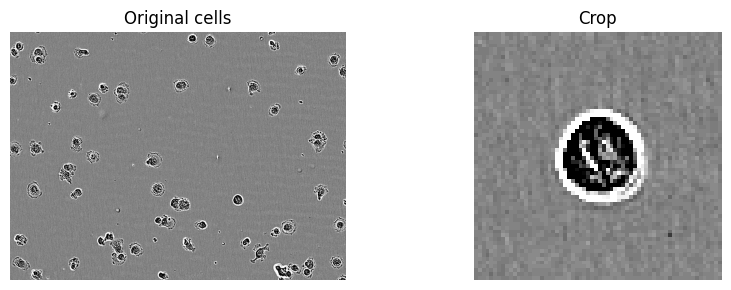

In [4]:
url = (
    "https://raw.githubusercontent.com/wonderalexandre/mmcfilters/"
    "main/dat/a172.png"
)
try:
    image_path, _ = urlretrieve(url)
except:
    image_path = "../dat/a172.png"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
assert image is not None, f"Could not read {image_path}"
image = np.ascontiguousarray(image, dtype=np.uint8)
crop = np.s_[320:384, 445:509]

figure, axes = plt.subplots(1, 2, figsize=(9, 3))
for axis, img, title in zip(axes, [image, image[crop]], ["Original cells", "Crop"]):
    axis.imshow(img, cmap="gray", vmin=0, vmax=255)
    axis.set_title(title)
    axis.axis("off")
figure.tight_layout()
plt.show()


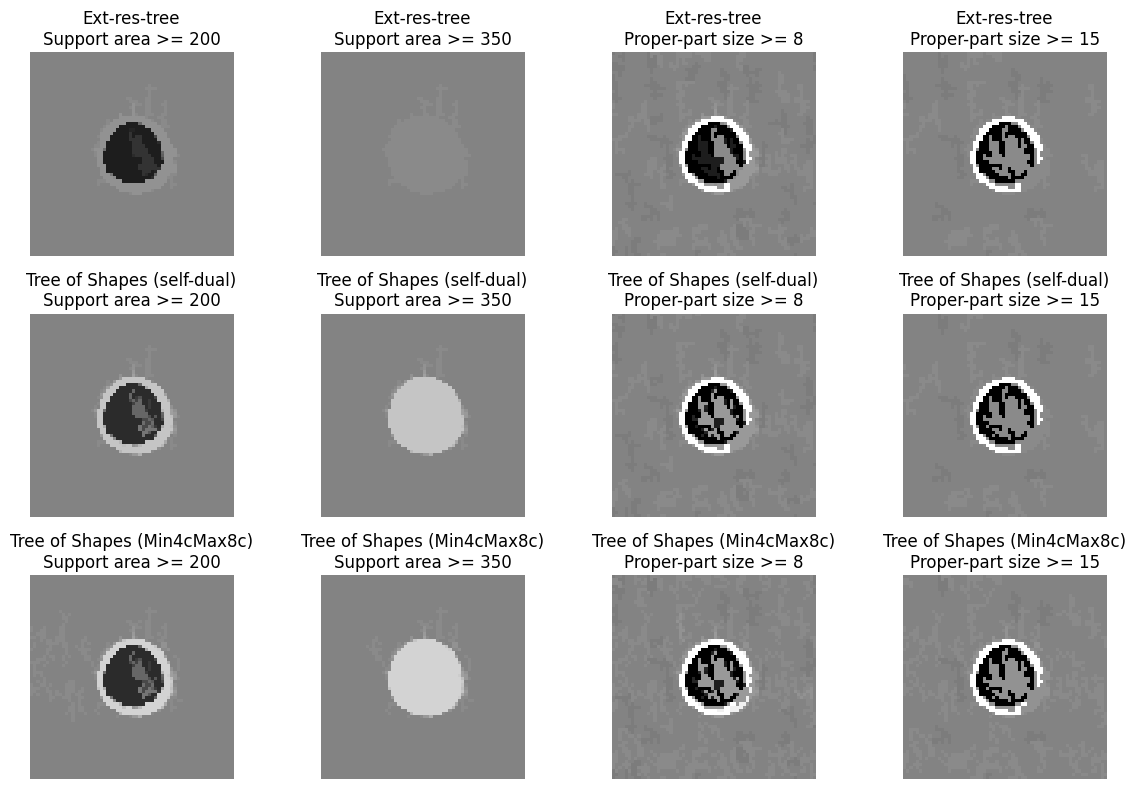

In [5]:
trees = {
    # 4-connectivity on the original image grid.
    "Ext-res-tree": factory.create_extremum_residual_tree(image, radius=adj4),

    # Self-dual span immersion (Boutry et al.).
    # 4-connectivity on the interpolated grid; doubled altitudes.
    # Padding enabled; p_infinity=0 defines the exterior reference.
    "Tree of Shapes (self-dual)": factory.create_tree_of_shapes(image, mmcfilters.self_dual_span_convention()),

    # Complementary-grid immersion on the interpolated grid.
    # 4-connectivity for lower level sets; 8-connectivity for upper level sets.
    # No padding; p_infinity=0 corresponds to the top-left original pixel.
    "Tree of Shapes (Min4cMax8c)": factory.create_tree_of_shapes(image),
}

figure, axes = plt.subplots(len(trees), 4, figsize=(12, 8))
filtered_images = {}

for tree_axes, (name, tree) in zip(axes, trees.items()):
    scale = 2 if name == "Tree of Shapes (self-dual)" else 1
    area = mmcfilters.Attribute.compute_single_topology_attribute(tree, mmcfilters.Attribute.AREA)
    proper_size = np.array([ len(tree.proper_part(node)) for node in tree.alive_node_ids ])
    examples = [
        ("Support area", area, 200),
        ("Support area", area, 350),
        ("Proper-part size", proper_size, 8),
        ("Proper-part size", proper_size, 15),
    ]
    for axis, (attribute, values, threshold) in zip(tree_axes, examples):
        keep = values >= threshold
        keep[tree.root] = True
        mask = mmcfilters.NodePreservationMask(keep.tolist())
        filtered = mmcfilters.DirectAttributeFilter(tree).apply(mask) / scale
        filtered_images[(name, attribute, threshold)] = filtered

        axis.imshow(filtered[crop], cmap="gray", vmin=0, vmax=255)
        axis.set_title(f"{name}\n{attribute} >= {threshold}")
        axis.axis("off")

figure.tight_layout()
plt.show()
